# 3. Customer value, expected value and targeting

**Goal.** Turn probabilities into a decision: a customer value proxy, the expected net value of each offer, and the list that maximises total expected value within a fixed budget, compared with simple rules such as "highest churn risk only".

Numbers in the text were generated for run `20261010T131542424757Z-88be4b93`.

In [1]:
import pandas as pd
from IPython.display import display, Image
from telco_retention.common import ROOT, latest_run, read_json
from telco_retention.business import campaign, default_offer, value_customers, offer_options
from telco_retention.analysis import campaign_budget, run_strategy
pd.set_option("display.precision", 3)
run = latest_run()
cfg = read_json(run / "manifest.json")["config"]
scores = pd.read_csv(run / "scorecard.csv").query("split == 'test'")
thresholds = read_json(run / "targeting_thresholds.json")
budget = campaign_budget(len(scores), cfg)
print("Run:", run.name, "| test customers:", len(scores), "| budget:", budget)

Run: 20261010T131542424757Z-88be4b93 | test customers: 1409 | budget: 3500.0


## Value proxy and expected value, by hand

Value = monthly charges x margin (30%) x discounted months (base 12 months x tenure factor, 10% a year). EV = p x save rate x value - (offer cost + contact cost). The cell recomputes three customers by hand and compares with the package.

In [2]:
offer = default_offer(cfg)
valued = value_customers(scores.head(3), cfg)
options = offer_options(valued, [offer])
hand = valued.assign(ev_by_hand=valued.churn_probability * offer["save_rate"] * valued.customer_value - (offer["offer_cost"] + offer["contact_cost"]))
display(hand[["customer_id", "MonthlyCharges", "tenure", "tenure_segment", "discounted_months", "customer_value", "churn_probability", "ev_by_hand"]])
assert (hand.ev_by_hand.round(9).values == options.expected_net_value.round(9).values).all()

,customer_id,MonthlyCharges,tenure,tenure_segment,discounted_months,customer_value,churn_probability,ev_by_hand
0,1452-KIOVK,89.10,22,developing,11.400,304.735,0.417,0.441
1,6713-OKOMC,29.75,10,new,8.651,77.214,0.330,-19.907
2,6388-TABGU,56.15,62,loyal,14.085,237.259,0.017,-24.204


## Same budget, different rules

,strategy,selected_count,cost,expected_net_value,roi,precision_contacted,high_risk_high_value_coverage,label_based_simulated_net
0,none,0.0,0.0,0.000,NaN,NaN,0.000,0.000
1,risk,140.0,3500.0,1098.185,0.314,0.700,0.039,774.709
2,risk_positive_ev,140.0,3500.0,1256.485,0.359,0.686,0.059,864.221
3,value,140.0,3500.0,-901.468,-0.258,0.286,0.294,89.901
4,ev,140.0,3500.0,2130.155,0.609,0.621,0.961,2083.025
5,segment_offers,152.0,3499.0,2420.147,0.692,0.599,1.000,2055.752
6,random_mean,140.0,3500.0,-1664.035,-0.475,0.262,0.102,-1688.310


,strategy,label_based_simulated_net,lower_95,upper_95
0,none,0.000,0.000,0.000
1,risk,774.709,254.653,1285.120
2,risk_positive_ev,864.221,336.508,1414.162
3,value,89.901,-785.682,1070.742
4,ev,2083.025,1262.037,3067.357
5,segment_offers,2055.752,1140.292,3111.104
6,ev minus risk,1308.316,509.202,2152.575
7,ev minus risk_positive_ev,1218.804,435.228,2037.839
8,segment_offers minus ev,-27.273,-371.951,316.092


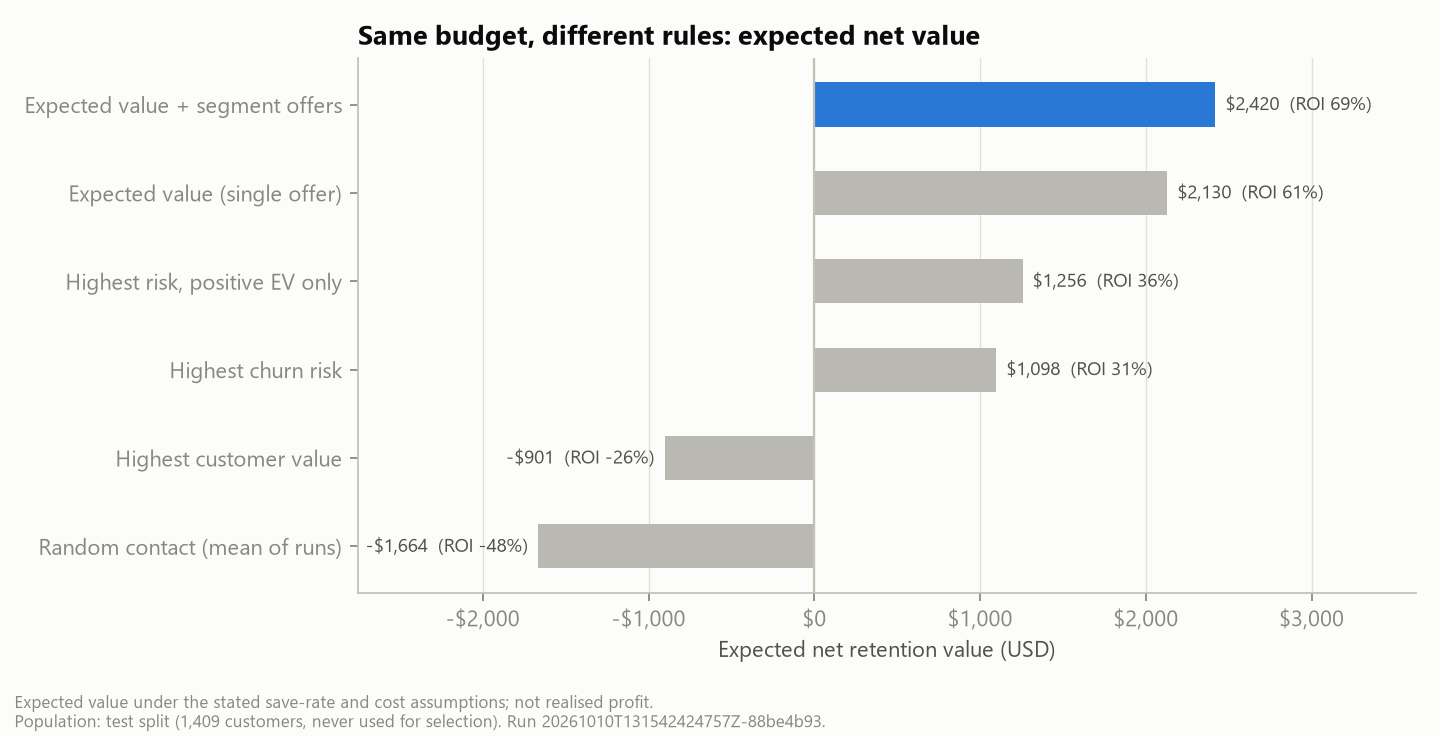

In [3]:
comparison = pd.read_csv(run / "strategy_comparison.csv")
display(comparison[["strategy", "selected_count", "cost", "expected_net_value", "roi", "precision_contacted", "high_risk_high_value_coverage", "label_based_simulated_net"]])
display(pd.read_csv(run / "economic_uncertainty.csv")[["strategy", "label_based_simulated_net", "lower_95", "upper_95"]])
display(Image(filename=str(ROOT / "reports/figures/strategy_comparison.png")))

**Interpretation.** With $3,500, risk-only earns $1,098 and expected-value targeting with the standard offer earns $2,130 (+$1,032). Checked against actual outcomes (paired bootstrap), the targeting gain is $1,308 with a 95% interval of $509 to $2,153. Risk-only has higher precision (70%) but reaches only 4% of high-risk, high-value customers.

## Segment-specific offers

In [4]:
display(pd.read_csv(run / "offer_catalog.csv"))
decisions = read_json(run / "validation_decisions.json")
display(pd.DataFrame(decisions["strategy_selection"]["validation"]).T[["selected_count", "cost", "expected_net_value", "roi"]])
print("Chosen on validation:", decisions["strategy_selection"]["strategy"], "| relative gain:", round(decisions["strategy_selection"]["relative_gain"], 3))
display(pd.read_csv(run / "segment_offer_mix.csv"))

,offer_id,label,offer_cost,contact_cost,save_rate,eligibility
0,standard,One-time $20 bill credit,20.0,5.0,0.20,All customers
1,contract_upgrade,$35 credit for moving to a 1-year contract,35.0,5.0,0.30,Contract in ['Month-to-month']
2,service_bundle,6 months free TechSupport + OnlineSecurity,12.0,5.0,0.15,"InternetService in ['DSL', 'Fiber optic']; Tec..."
3,loyalty_reward,$10 loyalty reward,10.0,5.0,0.10,tenure_segment in ['loyal']


,selected_count,cost,expected_net_value,roi
ev,140,3500.0,2157.549,0.616
segment_offers,156,3500.0,2417.614,0.691


Chosen on validation: segment_offers | relative gain: 0.121


,tenure_segment,Contract,offer_id,customers
0,new,Month-to-month,contract_upgrade,5
1,new,Month-to-month,service_bundle,45
2,new,Month-to-month,standard,2
3,developing,Month-to-month,contract_upgrade,10
4,developing,Month-to-month,service_bundle,18
5,loyal,Month-to-month,contract_upgrade,22
6,loyal,Month-to-month,service_bundle,44
7,loyal,Month-to-month,standard,6


**Interpretation.** The optimiser (a knapsack solved exactly with HiGHS) chooses at most one eligible offer per customer. On validation, segment offers beat the single offer by 12%, so the recommended rule is **expected value + segment offers**. On test the extra expected value is $290; with actual outcomes it is -$27, i.e. not distinguishable from zero. The offer-design gain rests on assumed save rates and must be tested.

## Who gets contacted

,quadrant,customers,customer_share,observed_churn,mean_probability,mean_customer_value,value_at_risk,value_at_risk_share,selected_risk,selected_ev,selected_segment_offers
0,High risk / High value,51,0.036,0.529,0.539,401.754,11065.118,0.119,2,49,51
1,High risk / Low value,293,0.208,0.604,0.650,212.735,40673.088,0.439,138,74,83
2,Low risk / High value,297,0.211,0.202,0.177,414.171,21765.652,0.235,0,17,18
3,Low risk / Low value,768,0.545,0.143,0.140,167.670,19200.257,0.207,0,0,0


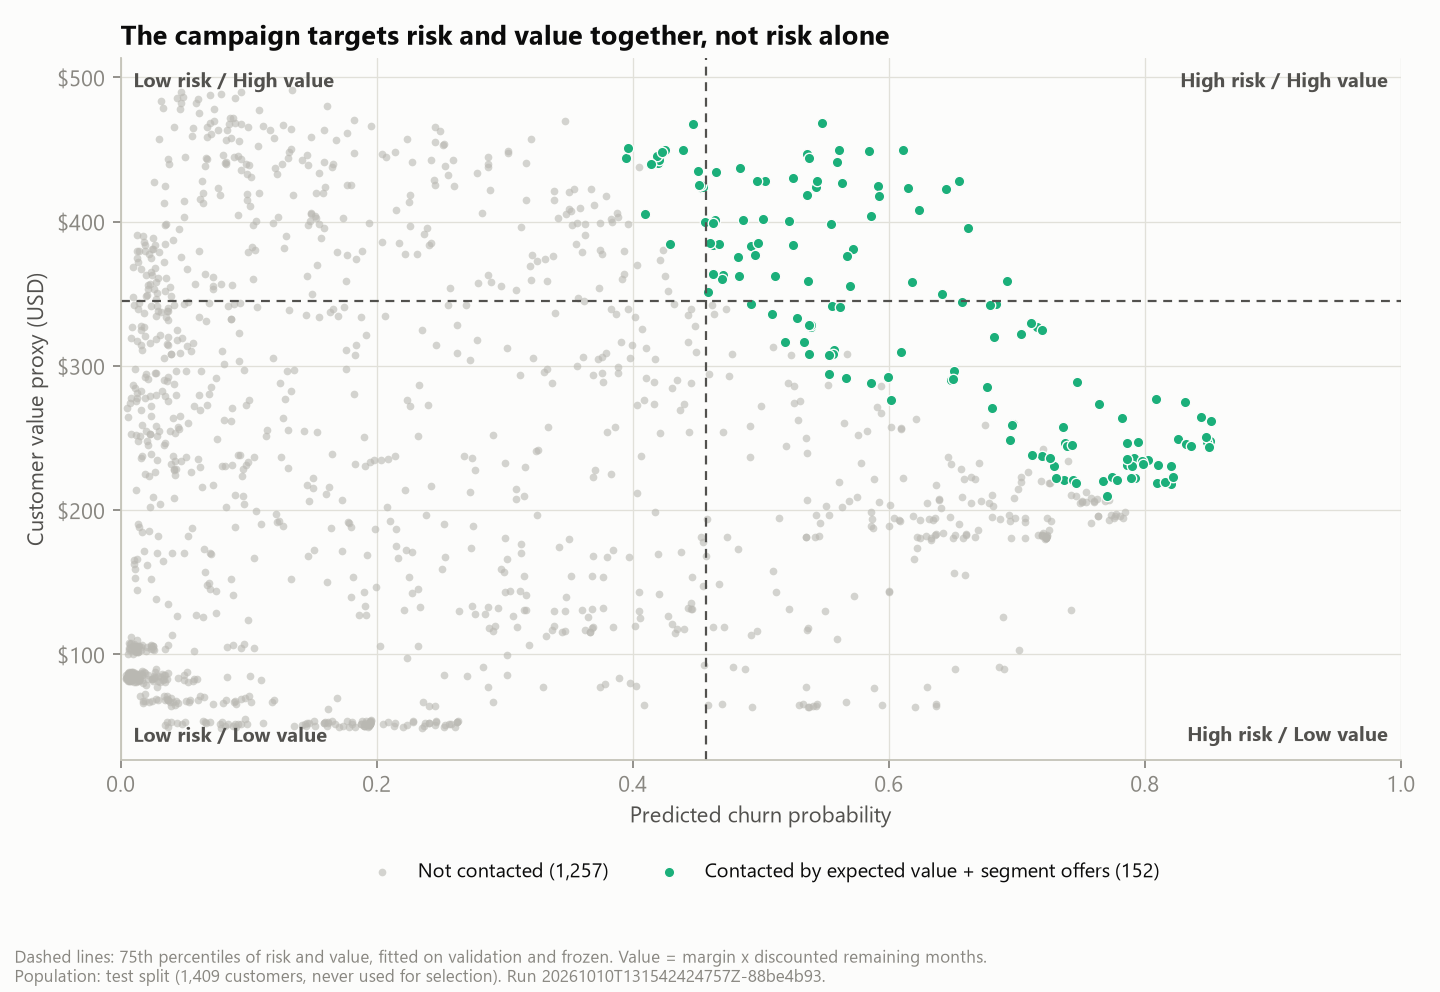

Scenario d081da7490e0 | matches the report: True


,customer_id,churn_probability,customer_value,offer_id,expected_net_value,decision_detail
403,2809-ZMYOQ,0.655,428.249,contract_upgrade,44.167,p=65.5% x save rate 30% x value 428.25 - cost ...
771,5380-WJKOV,0.611,449.377,contract_upgrade,42.356,p=61.1% x save rate 30% x value 449.38 - cost ...
1171,8397-MVTAZ,0.645,422.756,contract_upgrade,41.782,p=64.5% x save rate 30% x value 422.76 - cost ...
44,0337-CNPZE,0.585,449.165,contract_upgrade,38.788,p=58.5% x save rate 30% x value 449.17 - cost ...
1031,7402-EYFXX,0.662,395.502,contract_upgrade,38.524,p=66.2% x save rate 30% x value 395.50 - cost ...
687,4817-VYYWS,0.615,423.390,contract_upgrade,38.090,p=61.5% x save rate 30% x value 423.39 - cost ...
853,6030-REHUX,0.548,468.391,contract_upgrade,36.961,p=54.8% x save rate 30% x value 468.39 - cost ...
964,6899-PPEEA,0.624,407.967,contract_upgrade,36.355,p=62.4% x save rate 30% x value 407.97 - cost ...
1247,8938-UMKPI,0.561,449.588,contract_upgrade,35.640,p=56.1% x save rate 30% x value 449.59 - cost ...
63,0434-CSFON,0.591,424.658,contract_upgrade,35.354,p=59.1% x save rate 30% x value 424.66 - cost ...


In [5]:
display(pd.read_csv(run / "risk_value_matrix.csv"))
display(Image(filename=str(ROOT / "reports/figures/risk_value.png")))
target, summary = run_strategy(scores, budget, cfg, decisions["strategy_selection"]["strategy"], thresholds)
print("Scenario", summary["scenario_id"], "| matches the report:", summary["scenario_id"] == read_json(run / "campaign_scenarios.json")[decisions["strategy_selection"]["strategy"]]["scenario_id"])
display(target.loc[target.selected].nlargest(10, "expected_net_value")[["customer_id", "churn_probability", "customer_value", "offer_id", "expected_net_value", "decision_detail"]])

**So what.** The customer-level targeting table (`reports/tables/targeting_segment_offers.csv`) and the churn scorecard (`reports/tables/scorecard.csv`) are the operational deliverables; every row carries its formula and scenario ID.